# Review 2 · Beijing air-quality clustering

**Question:** Do the hourly pollution and weather readings from 12 Beijing monitoring stations form distinct environmental patterns? This notebook fits K-Means and agglomerative hierarchical clustering, compares them on the same observations, and interprets the resulting groups. There are no class labels in training.

Run every cell in order from the `notebooks/` directory. The shared implementation is in `src/clustering.py`; this notebook makes every analysis stage and its outputs visible.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'data' / 'clustering').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.clustering import load_stations, engineer_features, run_clustering, save_outputs, POLLUTANTS, WEATHER
sns.set_theme(style='whitegrid', palette='colorblind')
print('Project root:', ROOT)

Matplotlib is building the font cache; this may take a moment.


Project root: /Users/harsha/.codex/.chatgpt-projects/g-p-6aca0fc6678081918c263066dd2978d4/review2_case_study


## 1. Data loading and audit

The source is the Beijing Multi-Site Air Quality dataset: hourly measurements from 12 stations, March 2013 to February 2017. The loader checks the schema, station names, and duplicate station timestamps. `No` and `station` are identifiers, not clustering features.

In [2]:
raw = load_stations(ROOT / 'data' / 'clustering')
print('Shape:', raw.shape)
print('Stations:', raw['station'].nunique())
print('Exact duplicate rows:', raw.duplicated().sum())
display(raw.head())
display(raw.dtypes.to_frame('dtype'))
display(raw.isna().sum().sort_values(ascending=False).to_frame('Missing values'))
display(raw['station'].value_counts().sort_index().to_frame('Rows'))

Shape: (420768, 18)
Stations: 12
Exact duplicate rows: 0


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


,dtype
No,int64
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64


,Missing values
CO,20701
O3,13277
NO2,12116
SO2,9021
PM2.5,8739
PM10,6449
wd,1822
DEWP,403
TEMP,398
PRES,393


,Rows
station,
Aotizhongxin,35064
Changping,35064
Dingling,35064
Dongsi,35064
Guanyuan,35064
Gucheng,35064
Huairou,35064
Nongzhanguan,35064
Shunyi,35064


## 2. Exploratory data analysis

Missingness varies by sensor and pollutant. We keep incomplete readings and impute numerical feature medians before clustering. Pollution has a long right tail, so the model uses `log1p` for each pollutant. Extreme nonnegative readings are retained because they may represent real pollution episodes; negative physical readings are treated as missing.

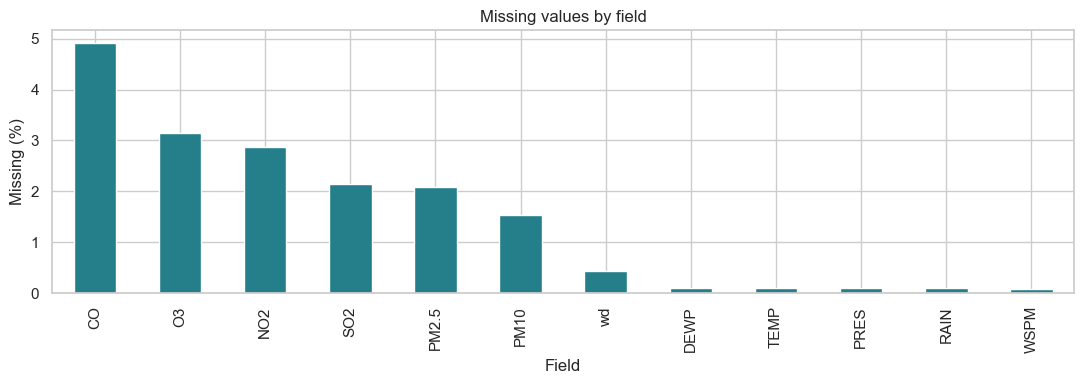

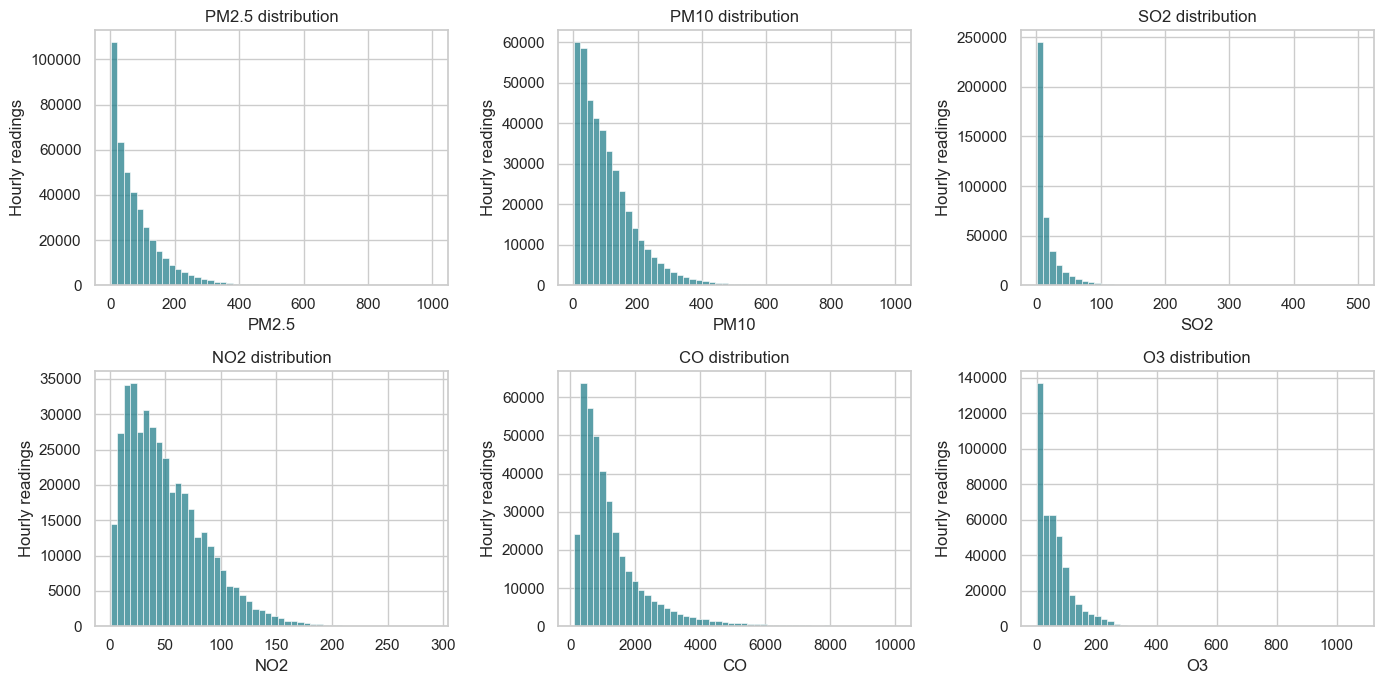

In [3]:
missing = raw.isna().mean().mul(100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 4))
missing[missing > 0].plot.bar(ax=ax, color='#247f8b')
ax.set(title='Missing values by field', xlabel='Field', ylabel='Missing (%)')
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for name, ax in zip(POLLUTANTS, axes.flat):
    sns.histplot(raw[name].dropna(), bins=50, ax=ax, color='#247f8b')
    ax.set(title=f'{name} distribution', xlabel=name, ylabel='Hourly readings')
fig.tight_layout(); plt.show()

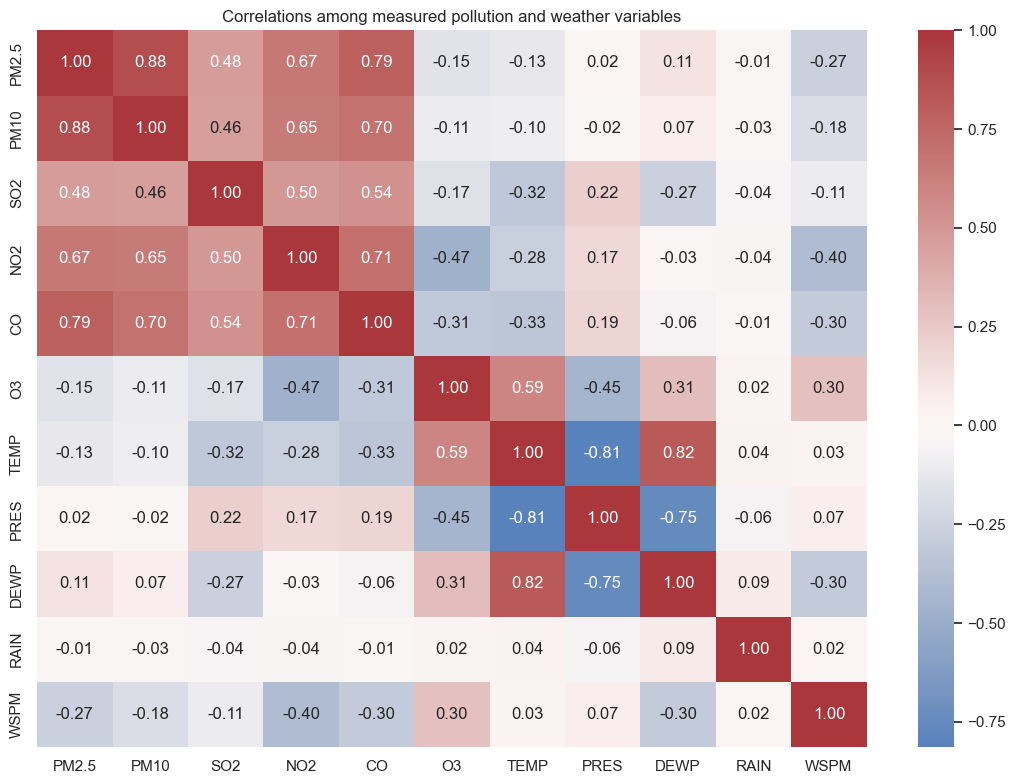

,PM2.5,PM10,SO2,NO2,CO,O3
station,,,,,,
Aotizhongxin,82.77,110.06,17.38,59.31,1262.95,56.35
Changping,71.10,94.66,14.96,44.18,1152.30,57.94
Dingling,65.99,83.74,11.75,27.59,904.90,68.55
Dongsi,86.19,110.34,18.53,53.70,1330.07,57.21
Guanyuan,82.93,109.02,17.59,57.90,1271.29,55.80
Gucheng,83.85,118.86,15.37,55.87,1323.97,57.69
Huairou,69.63,91.48,12.12,32.50,1022.55,59.82
Nongzhanguan,84.84,108.99,18.69,58.10,1324.35,58.53
Shunyi,79.49,98.74,13.57,43.91,1187.06,55.20


In [4]:
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(raw[POLLUTANTS + WEATHER].corr(), cmap='vlag', center=0,
            annot=True, fmt='.2f', ax=ax)
ax.set(title='Correlations among measured pollution and weather variables')
fig.tight_layout(); plt.show()
display(raw.groupby('station')[POLLUTANTS].mean().round(2))

## 3. Feature engineering and preprocessing

Hour, month, and wind direction are cyclic. Sine/cosine pairs keep nearby directions and boundary times close. Six pollutants are log transformed; five weather measurements remain in their original scale until standardization. Median imputation and scaling are fitted on the unsupervised dataset; there is no target or test split to leak into clustering.

In [5]:
engineered = engineer_features(raw)
print('Feature matrix:', engineered.shape)
print('Features:', engineered.columns.tolist())
display(engineered.isna().sum().to_frame('Missing before imputation'))
display(engineered.head())

Feature matrix: (420768, 17)
Features: ['PM2.5_log', 'PM10_log', 'SO2_log', 'NO2_log', 'CO_log', 'O3_log', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'wd_sin', 'wd_cos']


,Missing before imputation
PM2.5_log,8739
PM10_log,6449
SO2_log,9021
NO2_log,12116
CO_log,20701
O3_log,13277
TEMP,398
PRES,393
DEWP,403
RAIN,390


,PM2.5_log,PM10_log,SO2_log,NO2_log,CO_log,O3_log,TEMP,PRES,DEWP,RAIN,WSPM,hour_sin,hour_cos,month_sin,month_cos,wd_sin,wd_cos
0,1.609438,1.609438,1.609438,2.079442,5.70711,4.356709,-0.7,1023.0,-18.8,0.0,4.4,0.000000,1.000000,0.866025,0.5,-0.382683,0.923880
1,2.197225,2.197225,1.609438,2.079442,5.70711,4.356709,-1.1,1023.2,-18.2,0.0,4.7,0.258819,0.965926,0.866025,0.5,0.000000,1.000000
2,2.079442,2.079442,1.791759,2.397895,5.70711,4.304065,-1.1,1023.5,-18.2,0.0,5.6,0.500000,0.866025,0.866025,0.5,-0.382683,0.923880
3,1.945910,1.945910,2.484907,2.484907,5.70711,4.290459,-1.4,1024.5,-19.4,0.0,3.1,0.707107,0.707107,0.866025,0.5,-0.707107,0.707107
4,1.386294,1.386294,2.564949,2.564949,5.70711,4.290459,-2.0,1025.2,-19.5,0.0,2.0,0.866025,0.500000,0.866025,0.5,0.000000,1.000000


## 4. K-Means and hierarchical clustering

K-Means is fitted on all available hourly readings. The elbow and candidate silhouette calculations use a reproducible 12,000-row selection sample, with 1,500 rows for silhouette scoring. The selected K maximizes sampled silhouette; the elbow curve provides a second visual check. Agglomerative clustering is fitted on a reproducible 3,000-row sample because pairwise merging has much higher cost. Both final algorithms are evaluated on **the same 3,000 rows**, using the same transformed features and all three required metrics.

In [6]:
result = run_clustering(raw)
print('Selected K:', result['best_k'])
print('K-Means cluster counts across all readings:')
display(pd.Series(result['all_labels']).value_counts().sort_index().to_frame('Rows'))
display(result['elbow'].round(4))

Selected K: 3
K-Means cluster counts across all readings:


,Rows
0,139243
1,190158
2,91367


,K,Inertia,Silhouette Score
0,2,164192.1042,0.1849
1,3,136434.7859,0.2074
2,4,126966.0651,0.1685
3,5,119934.5792,0.1536
4,6,113145.2589,0.1547
5,7,108397.2490,0.1427


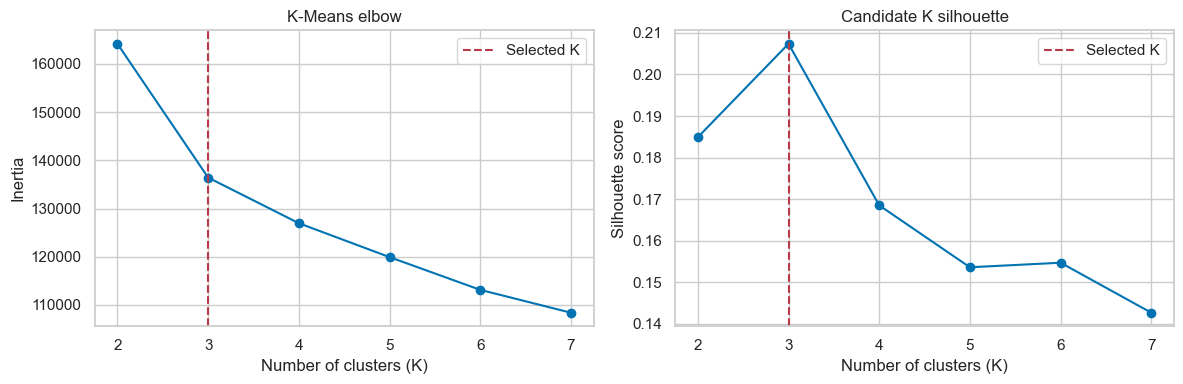

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(result['elbow']['K'], result['elbow']['Inertia'], marker='o')
axes[0].set(title='K-Means elbow', xlabel='Number of clusters (K)', ylabel='Inertia')
axes[1].plot(result['elbow']['K'], result['elbow']['Silhouette Score'], marker='o')
axes[1].set(title='Candidate K silhouette', xlabel='Number of clusters (K)', ylabel='Silhouette score')
for ax in axes: ax.axvline(result['best_k'], color='#b83a48', linestyle='--', label='Selected K'); ax.legend()
fig.tight_layout(); plt.show()

### Hierarchical linkage analysis

Ward, complete, and average linkage are compared on the same sample. Ward is retained for the final hierarchical solution because it controls within-cluster variance and yields a direct comparison with K-Means' compact-cluster objective. The dendrogram displays the Ward merge structure on 1,000 sampled readings.

,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,ward,0.1710,1.6598,575.5983
1,complete,0.3162,0.7814,49.2475
2,average,0.3165,0.8024,47.7488


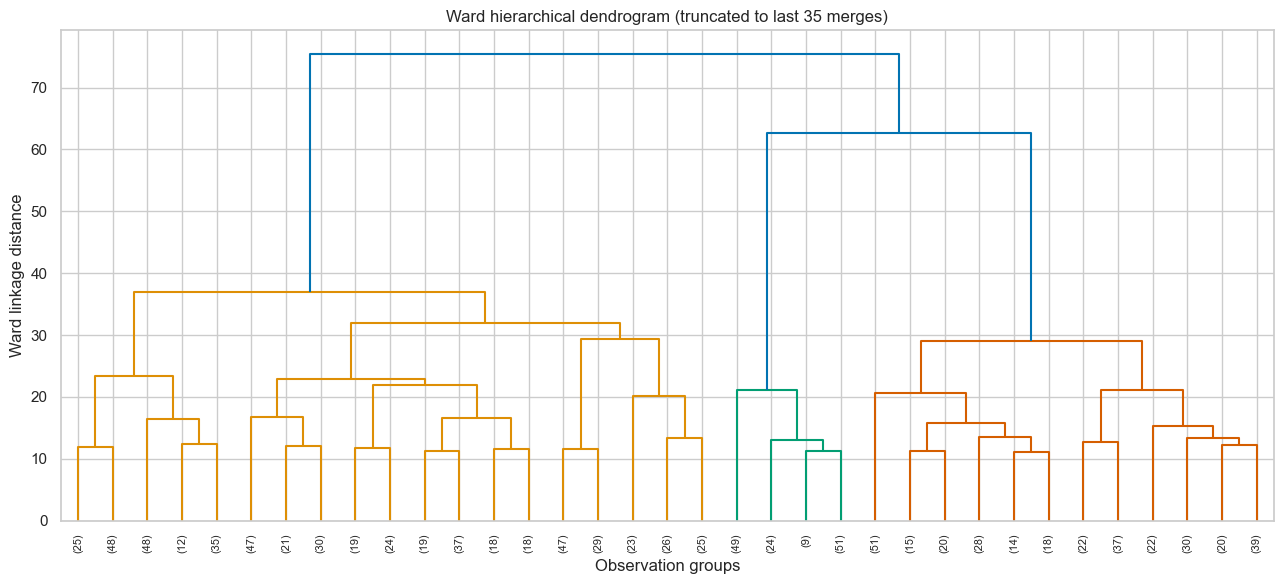

In [8]:
display(result['linkage_table'].round(4))
fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(result['dendrogram_linkage'], truncate_mode='lastp', p=35,
           leaf_rotation=90, ax=ax)
ax.set(title='Ward hierarchical dendrogram (truncated to last 35 merges)',
       xlabel='Observation groups', ylabel='Ward linkage distance')
fig.tight_layout(); plt.show()

## 5. Comparative evaluation

Higher silhouette and Calinski-Harabasz scores and lower Davies-Bouldin scores indicate stronger separation under these definitions. These are internal metrics, not proof of physical or health categories. The common evaluation rows make the two algorithms directly comparable.

In [9]:
display(result['comparison'].round(4))

,Algorithm,Clusters,Evaluation Rows,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,3,3000,0.2069,1.5907,743.2729
1,Agglomerative (Ward),3,3000,0.1710,1.6598,575.5983


## 6. Two-component PCA and t-SNE views

PCA projects the same 3,000 comparison readings into two dimensions. Colour indicates the cluster assignment from each algorithm; clustering itself uses all 17 standardized features. t-SNE is an additional local-structure view for a reproducible 1,200-row K-Means sample. Neither projection is used to fit the clustering models.

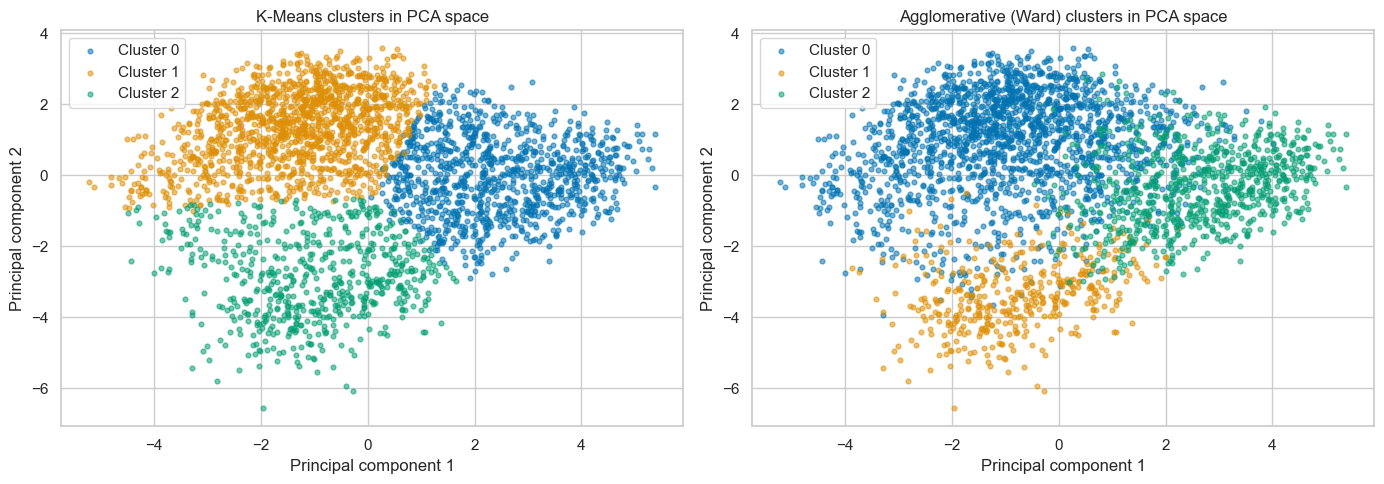

PCA explained variance: [0.2701 0.22  ] total 0.4901


In [10]:
points = result['pca_points']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, labels, name in [
    (axes[0], result['kmeans_common'], 'K-Means'),
    (axes[1], result['hierarchy_common'], 'Agglomerative (Ward)')]:
    for cluster in np.unique(labels):
        mask = labels == cluster
        ax.scatter(points[mask, 0], points[mask, 1], s=12, alpha=.55,
                   label=f'Cluster {cluster}')
    ax.set(title=f'{name} clusters in PCA space', xlabel='Principal component 1',
           ylabel='Principal component 2')
    ax.legend()
fig.tight_layout(); plt.show()
print('PCA explained variance:', result['pca'].explained_variance_ratio_.round(4),
      'total', result['pca'].explained_variance_ratio_.sum().round(4))

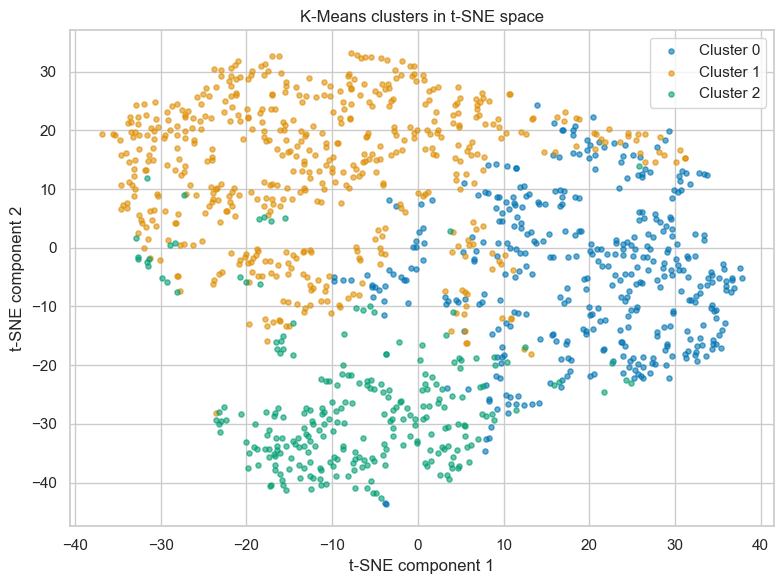

In [11]:
tsne_labels = result['kmeans_common'][result['tsne_indices']]
fig, ax = plt.subplots(figsize=(8, 6))
for cluster in np.unique(tsne_labels):
    mask = tsne_labels == cluster
    ax.scatter(result['tsne_points'][mask, 0], result['tsne_points'][mask, 1],
               s=14, alpha=.6, label=f'Cluster {cluster}')
ax.set(title='K-Means clusters in t-SNE space', xlabel='t-SNE component 1',
       ylabel='t-SNE component 2')
ax.legend(); fig.tight_layout(); plt.show()

## 7. Interpretation and export

The profile table reports original-unit pollutant and weather means, together with cluster sizes. It helps describe each numerical cluster without treating its arbitrary index as a quality label. Monitoring station is used only for this post-fit interpretation. We save the fitted preprocessing and K-Means model for the interactive application.

,Observations,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
Cluster,,,,,,,,,,,,
0,139243,138.80,167.25,31.57,83.44,2223.71,16.76,4.65,1016.95,-3.69,0.01,1.19
1,190158,67.33,91.48,8.36,40.02,888.58,87.21,23.58,1002.26,14.28,0.13,1.59
2,91367,15.62,36.46,7.25,22.55,425.45,56.86,6.18,1018.97,-12.66,0.01,2.84


station,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
row_0,,,,,,,,,,,,
0,9.0,7.4,5.9,8.8,8.9,9.0,6.9,9.0,8.1,8.7,9.6,8.9
1,8.1,8.8,8.7,8.1,8.3,8.5,8.9,8.0,8.1,8.2,8.1,8.2
2,7.8,8.9,11.3,8.2,7.7,6.9,9.5,8.0,9.0,7.9,6.9,7.7


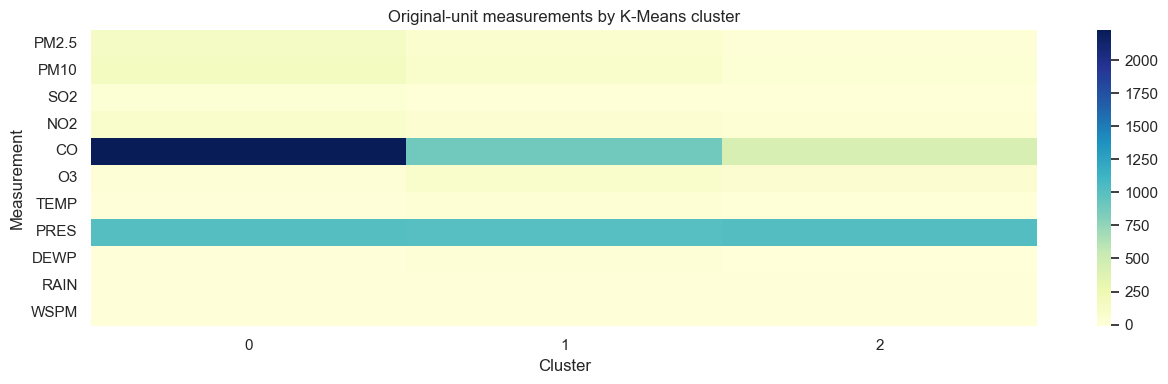

Saved comparison, plots data, profiles, and prediction model under results/ and models/.


In [12]:
display(result['profile'].round(2))
station_mix = pd.crosstab(result['all_labels'], raw['station'], normalize='index') * 100
display(station_mix.round(1))
fig, ax = plt.subplots(figsize=(13, 4))
sns.heatmap(result['profile'][POLLUTANTS + WEATHER].T, cmap='YlGnBu', ax=ax)
ax.set(title='Original-unit measurements by K-Means cluster', xlabel='Cluster', ylabel='Measurement')
fig.tight_layout(); plt.show()
save_outputs(result, ROOT)
print('Saved comparison, plots data, profiles, and prediction model under results/ and models/.')

## Conclusion and limitations

The comparison table above summarizes the two required algorithms on the same observations. The elbow, dendrogram, PCA views, and t-SNE view show different aspects of cluster structure. Cluster counts and environmental profiles should be interpreted with their actual values above; their integer labels carry no inherent ranking. Agglomerative labels apply only to the 3,000-row sample, while K-Means assigns every reading. Silhouette and PCA are descriptive tools, and no ground-truth air-quality class was supplied for validation.